# 00 · Get and check the data

The dataset is on Zenodo (DOI to be added). Run `python scripts/download_data.py` once; it fills `data/raw/`.
This notebook checks that everything the other notebooks need is present and unchanged.

| | |
|---|---|
| **Inputs** | `data/raw/` (or `$VISIONCRACK_DATA`) |
| **Outputs** | none |
| **Runtime** | ~10 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


In [ ]:
import importlib.util, sys
root = io.data_dir()
print('data dir:', root.relative_to(io.repo_root()) if root.is_relative_to(io.repo_root()) else '$VISIONCRACK_DATA')
expected = {'table1_et/images': ('*.png', 10), 'robustness/norm': ('*.jpg', 4), 'robustness/dist': ('*.jpg', 6),
            'robustness/roll': ('*.jpg', 12), 'robustness/pitch': ('*.jpg', 11), 'robustness/yaw': ('*.jpg', 12)}
rows = [{'folder': k, 'expected': n, 'found': len(list((root / k).glob(pat)))} for k, (pat, n) in expected.items()]
check = pd.DataFrame(rows); check['ok'] = check.found == check.expected
check

data dir: data/raw


,folder,expected,found,ok
0,table1_et/images,10,10,True
1,robustness/norm,4,4,True
2,robustness/dist,6,6,True
3,robustness/roll,12,12,True
4,robustness/pitch,11,11,True
5,robustness/yaw,12,12,True


In [ ]:
spec = importlib.util.spec_from_file_location('dl', io.repo_root() / 'scripts' / 'download_data.py')
dl = importlib.util.module_from_spec(spec); spec.loader.exec_module(dl)
if (root / 'MANIFEST.md5').exists():
    assert dl.verify(root), 'some files differ from the published dataset'
else:
    print('no MANIFEST.md5 here (sample data or a local copy); skipping checksum verification')

all files verified


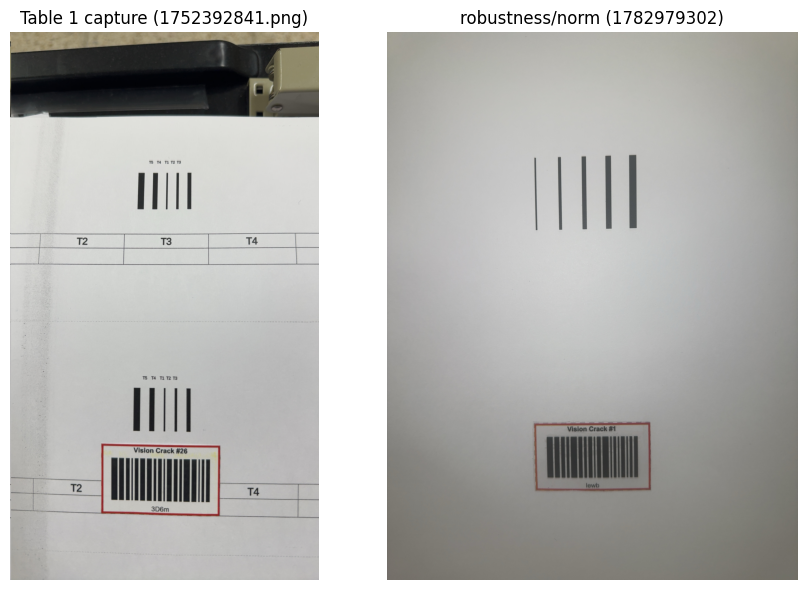

,ET-1,ET-2,ET-3,ET-4,ET-5
inspector,,,,,
Inspector 1,0.50,1.40,1.90,2.40,2.90
Inspector 2,0.50,1.00,2.00,2.50,3.00
Inspector 3,0.50,1.30,1.90,2.40,3.00
Inspector 4,0.55,1.50,2.00,2.50,3.00
Inspector 5,0.50,1.00,2.00,2.50,3.00
Inspector 6,0.60,1.40,2.00,2.50,2.90
Inspector 7,0.53,1.25,1.75,2.25,3.25
Inspector 8,0.55,1.25,1.75,2.25,2.75
Inspector 9,0.62,1.30,1.70,2.30,2.60


In [ ]:
caps, inspectors = vc.load_table1()
fig, ax = plt.subplots(1, 2, figsize=(9, 6))
ax[0].imshow(vc.read_rgb(caps.path[0])); ax[0].set_title(f'Table 1 capture ({caps.image[0]})')
sweep_imgs = sorted((root / 'robustness' / 'norm').glob('*.jpg'))
if sweep_imgs:
    ax[1].imshow(vc.read_rgb(sweep_imgs[0])); ax[1].set_title(f'robustness/norm ({sweep_imgs[0].name[:10]})')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
inspectors